# SecureCloud AI — Module ML : détection d'anomalies (baseline, comparaison, évaluation)

Notebook reproductible (à exécuter de haut en bas). Protocole conforme au cahier des charges :
**entraînement sur événements normaux uniquement → validation (réglages + seuil) → test utilisé une seule fois**.
Les étiquettes ne servent jamais à entraîner un détecteur.

> ⚠️ Jeu de données **synthétique** (`generate_dataset.py`) : les résultats mesurent la méthode, pas la performance sur de vrais journaux AWS.

## 1. Configuration

In [1]:
import json, time, importlib.util, warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib, numpy as np, pandas as pd, sklearn
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_recall_curve

from ml_utils import MahalanobisDetector, anomaly_score, best_threshold, summarize

warnings.filterwarnings("ignore")
SEED = 42
DATA_PATH, MODEL_PATH, METRICS_PATH = Path("dataset.csv"), Path("model.joblib"), Path("metrics.json")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
MIN_F1, MIN_RECALL = 0.80, 0.85          # quality gate (informatif)
np.random.seed(SEED)
print("sklearn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

sklearn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 2. Chargement et inventaire des données

In [2]:
spec = importlib.util.spec_from_file_location("generate_dataset", "generate_dataset.py")
gen = importlib.util.module_from_spec(spec); spec.loader.exec_module(gen)
FEATURES = list(gen.FEATURES)

if DATA_PATH.exists():
    df = pd.read_csv(DATA_PATH)
else:
    df = gen.build(SEED); df.to_csv(DATA_PATH, index=False); print("dataset généré")

print(f"{len(df):,} lignes | {df.shape[1]} colonnes | variables du modèle : {FEATURES}")
display(df.dtypes.to_frame("type").join(df.isna().sum().rename("valeurs_manquantes")))
display(df.groupby(["split", "label"]).size().unstack(fill_value=0))
display(df.groupby("scenario").size().to_frame("n"))
assert not df[FEATURES].isna().any().any() and np.isfinite(df[FEATURES].to_numpy(float)).all()

8,360 lignes | 10 colonnes | variables du modèle : ['event_count', 'guardduty_count', 'max_severity', 'mean_severity', 'sg_change_count', 'distinct_event_types', 'mean_event_gap_s']


,type,valeurs_manquantes
event_count,int64,0
guardduty_count,int64,0
max_severity,float64,0
mean_severity,float64,0
sg_change_count,int64,0
distinct_event_types,int64,0
mean_event_gap_s,float64,0
label,int64,0
scenario,str,0
split,str,0


label,0,1
split,,
contam,0,600
test,1200,180
train,5000,0
val,1200,180


,n
scenario,
critical_single,136
guardduty_burst,294
mixed,259
normal,7400
sg_tampering,271


## 3. Fuite de données et doublons
* `label`, `scenario`, `split` ne sont **pas** des variables du modèle (seuls `FEATURES` sont utilisées) ; il n'y a ni identifiant ni horodatage brut dans les variables.
* Les doublons sont supprimés **dans** chaque ensemble puis **entre** ensembles (priorité train > val > test ; le pool `contam` est dédoublonné contre tout le reste).

In [3]:
print("Variables du modèle :", FEATURES)
print("Colonnes exclues (étiquettes/méta) :", [c for c in df.columns if c not in FEATURES])
corr = df[FEATURES].corrwith(df["label"], method="spearman").round(3).to_frame("spearman_vs_label")
display(corr)   # contrôle : aucune variable ne doit être une copie de l'étiquette

before = df.groupby("split").size()
n_dup = int(df.duplicated(FEATURES).sum())
seen, kept = set(), []
for split in ["train", "val", "test", "contam"]:
    part = df[df["split"] == split].drop_duplicates(FEATURES)
    keys = list(map(tuple, part[FEATURES].to_numpy()))
    mask = [k not in seen for k in keys]
    part = part[mask]; seen.update(k for k, m in zip(keys, mask) if m); kept.append(part)
df_raw, df = df, pd.concat(kept, ignore_index=True)

after = df.groupby("split").size()
print(f"Lignes dupliquées avant nettoyage : {n_dup}")
display(pd.DataFrame({"avant": before, "après": after}))
train_df, val_df, test_df, contam_df = (df[df["split"] == s].copy() for s in ["train", "val", "test", "contam"])
# vérifications du protocole
K = lambda d: set(map(tuple, d[FEATURES].to_numpy()))
assert not (K(train_df) & K(val_df)) and not (K(train_df) & K(test_df)) and not (K(val_df) & K(test_df))
assert (train_df["label"] == 0).all(), "le train doit être 100 % normal"
print("OK : aucun doublon entre ensembles, train 100 % normal.")
display(df.groupby(["split", "label"]).size().unstack(fill_value=0))

Variables du modèle : ['event_count', 'guardduty_count', 'max_severity', 'mean_severity', 'sg_change_count', 'distinct_event_types', 'mean_event_gap_s']
Colonnes exclues (étiquettes/méta) : ['label', 'scenario', 'split']


,spearman_vs_label
event_count,0.402
guardduty_count,0.568
max_severity,0.594
mean_severity,0.591
sg_change_count,0.419
distinct_event_types,0.316
mean_event_gap_s,-0.345


Lignes dupliquées avant nettoyage : 66


,avant,après
split,,
contam,600,600
test,1380,1356
train,5000,4971
val,1380,1367


OK : aucun doublon entre ensembles, train 100 % normal.

label,0,1
split,,
contam,0,600
test,1176,180
train,4971,0
val,1187,180


## 4. Prétraitement
Variables toutes numériques (pas d'encodage nécessaire). `StandardScaler` **ajusté sur le train normal uniquement**, intégré dans un `Pipeline` pour être réutilisé à l'inférence.

In [4]:
X_train = train_df[FEATURES].to_numpy(float)
X_val, y_val = val_df[FEATURES].to_numpy(float), val_df["label"].to_numpy(int)
X_test, y_test = test_df[FEATURES].to_numpy(float), test_df["label"].to_numpy(int)
print("train", X_train.shape, "| val", X_val.shape, f"(attaques {y_val.mean():.1%})", "| test", X_test.shape, f"(attaques {y_test.mean():.1%})")

train (4971, 7) | val (1367, 7) (attaques 13.2%) | test (1356, 7) (attaques 13.3%)


## 5. Détecteurs : baseline, modèle principal, comparaison
* **Baseline** : distance de Mahalanobis (moyenne/covariance du trafic normal).
* **Modèle principal** : Isolation Forest.
* **Comparaison** : Local Outlier Factor (mode *novelty*) et One-Class SVM.

Réglage des hyperparamètres sur la **validation** (PR-AUC, étiquettes de validation uniquement) via une petite grille.

In [5]:
from sklearn.metrics import average_precision_score

def make(name, **p):
    if name == "Baseline Mahalanobis": return MahalanobisDetector()
    if name == "Isolation Forest":
        return make_pipeline(StandardScaler(), IsolationForest(n_estimators=300, random_state=SEED, n_jobs=1, **p))
    if name == "LOF (novelty)":
        return make_pipeline(StandardScaler(), LocalOutlierFactor(novelty=True, **p))
    if name == "One-Class SVM":
        return make_pipeline(StandardScaler(), OneClassSVM(kernel="rbf", gamma="scale", **p))

GRIDS = {"Baseline Mahalanobis": [{}],
         "Isolation Forest": [{"max_samples": m} for m in (128, 256, 1024)],
         "LOF (novelty)": [{"n_neighbors": k} for k in (20, 35, 60)],
         "One-Class SVM": [{"nu": v} for v in (0.01, 0.05, 0.1)]}

models, best_params, val_scores, timing, grid_log = {}, {}, {}, {}, []
for name, grid in GRIDS.items():
    best = None
    for p in grid:
        m = make(name, **p); t0 = time.perf_counter(); m.fit(X_train); fit_s = time.perf_counter() - t0
        s = anomaly_score(m, X_val); ap = average_precision_score(y_val, s)
        grid_log.append({"detecteur": name, "params": str(p), "PR-AUC validation": round(ap, 4)})
        if best is None or ap > best[0]: best = (ap, p, m, s, fit_s)
    _, best_params[name], models[name], val_scores[name], fit_s = best
    timing[name] = {"fit_s": fit_s}
display(pd.DataFrame(grid_log))
print("Hyperparamètres retenus (validation) :", best_params)

,detecteur,params,PR-AUC validation
0,Baseline Mahalanobis,{},0.9390
1,Isolation Forest,{'max_samples': 128},0.9461
2,Isolation Forest,{'max_samples': 256},0.9468
3,Isolation Forest,{'max_samples': 1024},0.9551
4,LOF (novelty),{'n_neighbors': 20},0.8460
5,LOF (novelty),{'n_neighbors': 35},0.8279
6,LOF (novelty),{'n_neighbors': 60},0.8274
7,One-Class SVM,{'nu': 0.01},0.9180
8,One-Class SVM,{'nu': 0.05},0.9484
9,One-Class SVM,{'nu': 0.1},0.9593


Hyperparamètres retenus (validation) : {'Baseline Mahalanobis': {}, 'Isolation Forest': {'max_samples': 1024}, 'LOF (novelty)': {'n_neighbors': 20}, 'One-Class SVM': {'nu': 0.1}}


## 6. Choix du seuil (validation uniquement)
Seuil = score qui maximise le F1 sur la validation. **Aucune étiquette de test n'est consultée.**
Comparaison de plusieurs seuils : courbes précision-rappel plus bas.

In [6]:
thresholds = {n: best_threshold(val_scores[n], y_val) for n in models}
display(pd.Series(thresholds, name="seuil (validation)").round(5).to_frame())

,seuil (validation)
Baseline Mahalanobis,6.09132
Isolation Forest,0.61983
LOF (novelty),1.46511
One-Class SVM,-25.93921


## 7. Évaluation finale sur le test (utilisé **une seule fois**)
Le tableau regroupe métriques, charge d'alertes pour 10 000 événements, part d'alertes réellement anormales (= précision) et temps d'exécution.

In [7]:
test_scores, rows, by_scenario = {}, [], {}
pos = test_df["label"].to_numpy() == 1
for name, m in models.items():
    t0 = time.perf_counter(); s = anomaly_score(m, X_test); timing[name]["score_s"] = time.perf_counter() - t0
    test_scores[name] = s
    pred = (s >= thresholds[name]).astype(int)
    r = summarize(y_test, pred, s)
    rows.append({"detecteur": name, "seuil": round(thresholds[name], 4), **r,
                 "fit_s": round(timing[name]["fit_s"], 3), "score_s": round(timing[name]["score_s"], 3)})
    by_scenario[name] = {sc: round(float(pred[pos & (test_df["scenario"].to_numpy() == sc)].mean()), 3)
                         for sc in sorted(test_df.loc[pos, "scenario"].unique())}

# Variante opérationnelle : Isolation Forest OU règle métier max_severity >= s* (s* choisi sur la VALIDATION)
s_if_val, s_if_test = val_scores["Isolation Forest"], test_scores["Isolation Forest"]
cands = np.arange(4.0, 9.6, 0.1)
f1v = [__import__("sklearn.metrics").metrics.f1_score(y_val, ((s_if_val >= thresholds["Isolation Forest"]) | (val_df["max_severity"].to_numpy() >= c)).astype(int)) for c in cands]
rule_sev = float(cands[int(np.argmax(f1v))])
pred_h = ((s_if_test >= thresholds["Isolation Forest"]) | (test_df["max_severity"].to_numpy() >= rule_sev)).astype(int)
rows.append({"detecteur": f"IF + règle (max_severity ≥ {rule_sev:.1f})", "seuil": round(thresholds["Isolation Forest"], 4),
             **summarize(y_test, pred_h), "fit_s": round(timing["Isolation Forest"]["fit_s"], 3), "score_s": np.nan})
by_scenario["IF + règle"] = {sc: round(float(pred_h[pos & (test_df["scenario"].to_numpy() == sc)].mean()), 3)
                             for sc in sorted(test_df.loc[pos, "scenario"].unique())}

results = pd.DataFrame(rows).set_index("detecteur")
display(results[["seuil", "precision", "recall", "f1", "pr_auc", "roc_auc", "tn", "fp", "fn", "tp", "alerts_per_10k", "fit_s", "score_s"]])
print("Rappel par famille d'attaque (test) :"); display(pd.DataFrame(by_scenario).T)
results.to_csv("results_table.csv")

,seuil,precision,recall,f1,pr_auc,roc_auc,tn,fp,fn,tp,alerts_per_10k,fit_s,score_s
detecteur,,,,,,,,,,,,,
Baseline Mahalanobis,6.0913,0.7783,0.8778,0.8251,0.9232,0.9831,1131,45,22,158,1497.1,0.005,0.000
Isolation Forest,0.6198,0.9034,0.8833,0.8933,0.9518,0.9896,1159,17,21,159,1297.9,0.609,0.060
LOF (novelty),1.4651,0.7403,0.7444,0.7424,0.8481,0.9588,1129,47,46,134,1334.8,0.127,0.046
One-Class SVM,-25.9392,0.9034,0.8833,0.8933,0.9591,0.9887,1159,17,21,159,1297.9,0.237,0.079
IF + règle (max_severity ≥ 6.4),0.6198,0.9034,0.8833,0.8933,NaN,NaN,1159,17,21,159,1297.9,0.609,NaN


Rappel par famille d'attaque (test) :


,critical_single,guardduty_burst,mixed,sg_tampering
Baseline Mahalanobis,0.926,0.981,0.913,0.717
Isolation Forest,0.889,1.000,1.000,0.660
LOF (novelty),0.370,0.852,0.870,0.717
One-Class SVM,0.852,0.963,0.978,0.736
IF + règle,0.889,1.000,1.000,0.660


## 8. Graphiques : distribution des scores, courbes précision-rappel, matrice de confusion

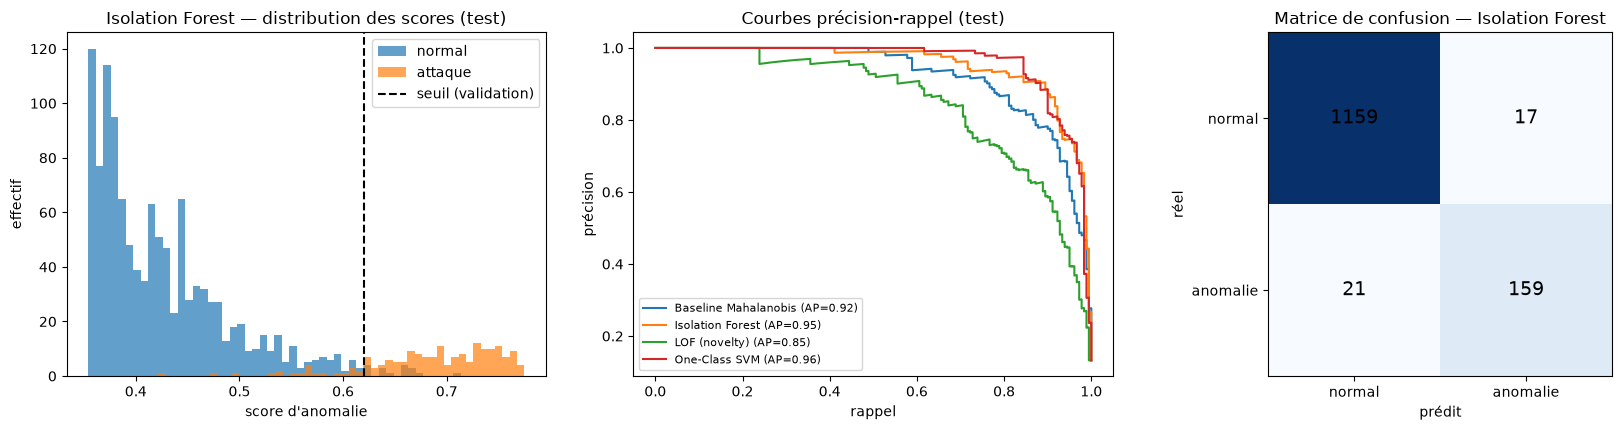

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
s = test_scores["Isolation Forest"]
ax[0].hist(s[y_test == 0], bins=50, alpha=.7, label="normal"); ax[0].hist(s[y_test == 1], bins=50, alpha=.7, label="attaque")
ax[0].axvline(thresholds["Isolation Forest"], color="k", ls="--", label="seuil (validation)")
ax[0].set(title="Isolation Forest — distribution des scores (test)", xlabel="score d'anomalie", ylabel="effectif"); ax[0].legend()
for n in models:
    p, r, _ = precision_recall_curve(y_test, test_scores[n]); ax[1].plot(r, p, label=f"{n} (AP={results.loc[n, 'pr_auc']:.2f})")
ax[1].set(title="Courbes précision-rappel (test)", xlabel="rappel", ylabel="précision"); ax[1].legend(fontsize=8)
cm = np.array([[results.loc["Isolation Forest", "tn"], results.loc["Isolation Forest", "fp"]],
               [results.loc["Isolation Forest", "fn"], results.loc["Isolation Forest", "tp"]]])
ax[2].imshow(cm, cmap="Blues"); ax[2].set(title="Matrice de confusion — Isolation Forest", xticks=[0, 1], yticks=[0, 1],
    xticklabels=["normal", "anomalie"], yticklabels=["normal", "anomalie"], xlabel="prédit", ylabel="réel")
for i in range(2):
    for j in range(2): ax[2].text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=14)
plt.tight_layout(); plt.savefig(FIG_DIR / "scores_pr_confusion.png", dpi=130); plt.show()

## 9. Expérience séparée : contamination de l'entraînement (1 % puis 5 %)
Des attaques issues d'un **pool indépendant** (`split == contam`) sont injectées dans l'entraînement. Le seuil est re-choisi sur la validation ; le test n'est utilisé que pour mesurer l'effet (aucun réglage n'en découle). 5 tirages par taux.

,detecteur,contamination,PR-AUC,F1,rappel,précision
0,Isolation Forest,0%,0.953 ± 0.000,0.897 ± 0.000,0.900,0.895
1,Isolation Forest,1%,0.955 ± 0.001,0.886 ± 0.007,0.880,0.892
2,Isolation Forest,5%,0.937 ± 0.003,0.855 ± 0.010,0.817,0.899
3,Baseline Mahalanobis,0%,0.923 ± 0.000,0.825 ± 0.000,0.878,0.778
4,Baseline Mahalanobis,1%,0.920 ± 0.000,0.822 ± 0.002,0.900,0.757
5,Baseline Mahalanobis,5%,0.887 ± 0.001,0.808 ± 0.007,0.812,0.807


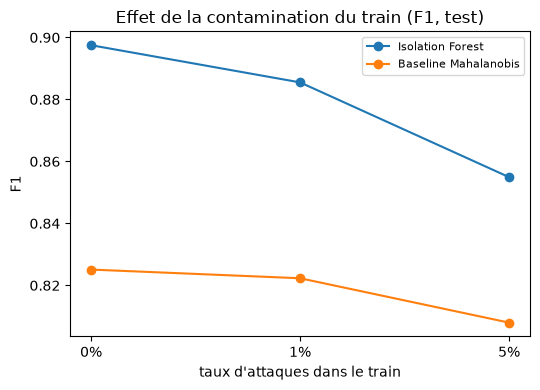

In [9]:
def run_contam(name, rate, seed):
    rng = np.random.default_rng(seed)
    k = int(round(rate / (1 - rate) * len(train_df))) if rate else 0
    extra = contam_df.sample(k, random_state=seed)[FEATURES].to_numpy(float) if k else np.empty((0, len(FEATURES)))
    Xc = np.vstack([X_train, extra]); rng.shuffle(Xc)
    m = make(name, **best_params[name]).fit(Xc)
    t = best_threshold(anomaly_score(m, X_val), y_val); s = anomaly_score(m, X_test)
    r = summarize(y_test, (s >= t).astype(int), s)
    return r["pr_auc"], r["f1"], r["recall"], r["precision"]

recs = []
for name in ["Isolation Forest", "Baseline Mahalanobis"]:
    for rate in (0.0, 0.01, 0.05):
        runs = np.array([run_contam(name, rate, SEED + i) for i in range(5 if rate else 1)])
        mu, sd = runs.mean(0), runs.std(0)
        recs.append({"detecteur": name, "contamination": f"{rate:.0%}", "PR-AUC": f"{mu[0]:.3f} ± {sd[0]:.3f}",
                     "F1": f"{mu[1]:.3f} ± {sd[1]:.3f}", "rappel": f"{mu[2]:.3f}", "précision": f"{mu[3]:.3f}",
                     "_pr": mu[0], "_f1": mu[1]})
contam_res = pd.DataFrame(recs); display(contam_res.drop(columns=["_pr", "_f1"]))
fig, ax = plt.subplots(figsize=(5.5, 4))
for name in contam_res["detecteur"].unique():
    d = contam_res[contam_res["detecteur"] == name]; ax.plot(d["contamination"], d["_f1"], marker="o", label=name)
ax.set(title="Effet de la contamination du train (F1, test)", xlabel="taux d'attaques dans le train", ylabel="F1"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "contamination.png", dpi=130); plt.show()
contam_res.drop(columns=["_pr", "_f1"]).to_csv("contamination_results.csv", index=False)

## 10. Export du modèle et contrat d'inférence
Sauvegarde : pipeline Isolation Forest (scaler inclus), variables, seuil, échelle des scores, statistiques de référence pour l'explication. `inference.py` expose `AnomalyDetector.predict()` → `correlation_id`, `anomaly_score`, `is_anomaly`, `priority`, `top_features`.

In [10]:
final = models["Isolation Forest"]
normal_val = val_scores["Isolation Forest"][y_val == 0]
scale = float(np.std(normal_val)) or 0.05
gate = bool(results.loc["Isolation Forest", "f1"] >= MIN_F1 and results.loc["Isolation Forest", "recall"] >= MIN_RECALL)
metrics = {
    "dataset": "synthetic (generate_dataset.py), duplicates removed within and across splits",
    "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df), "n_duplicates_removed": n_dup,
    "features": FEATURES, "seed": SEED, "best_params": best_params,
    "thresholds": {k: round(v, 5) for k, v in thresholds.items()},
    "test_results": json.loads(results.reset_index().to_json(orient="records")),
    "recall_by_scenario": by_scenario, "contamination": contam_res.drop(columns=["_pr", "_f1"]).to_dict("records"),
    "gate": {"min_f1": MIN_F1, "min_recall": MIN_RECALL, "isolation_forest_passed": gate},
}
bundle = {"model": final, "features": FEATURES, "threshold": float(thresholds["Isolation Forest"]), "scale": scale,
          "ref_mean": X_train.mean(0), "ref_std": X_train.std(0) + 1e-9, "metrics": metrics,
          "sklearn_version": sklearn.__version__, "trained_at": datetime.now(timezone.utc).isoformat()}
joblib.dump(bundle, MODEL_PATH); METRICS_PATH.write_text(json.dumps(metrics, indent=2, ensure_ascii=False), encoding="utf-8")
print("Modèle et métriques sauvegardés. Quality gate (Isolation Forest) :", "PASSED" if gate else "FAILED")

Modèle et métriques sauvegardés. Quality gate (Isolation Forest) : PASSED


In [11]:
from inference import AnomalyDetector
det = AnomalyDetector(MODEL_PATH)
examples = [
    {"correlation_id": "w-normal", "event_count": 3, "guardduty_count": 0, "max_severity": 0.0, "mean_severity": 0.0, "sg_change_count": 0, "distinct_event_types": 1, "mean_event_gap_s": 70.0},
    {"correlation_id": "w-attack", "event_count": 18, "guardduty_count": 11, "max_severity": 8.2, "mean_severity": 7.0, "sg_change_count": 2, "distinct_event_types": 3, "mean_event_gap_s": 12.0},
]
print(json.dumps(det.predict(examples), indent=2))

[
  {
    "correlation_id": "w-normal",
    "anomaly_score": 0.3559,
    "is_anomaly": false,
    "priority": "none",
    "top_features": [
      {
        "feature": "mean_event_gap_s",
        "z_vs_normal": -0.5
      },
      {
        "feature": "sg_change_count",
        "z_vs_normal": -0.45
      }
    ]
  },
  {
    "correlation_id": "w-attack",
    "anomaly_score": 0.76587,
    "is_anomaly": true,
    "priority": "high",
    "top_features": [
      {
        "feature": "guardduty_count",
        "z_vs_normal": 16.11
      },
      {
        "feature": "mean_severity",
        "z_vs_normal": 6.81
      }
    ]
  }
]
